In [1]:
import os
import sys
sys.path.insert(0, "./cellular_cycle") # add path to the model

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime

## Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count

# to match Austin's ouput and use his functions, simulation with ODE should use omega=1 and stochastic with omega=200 (the default)
from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

In [ ]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt(os.getcwd() + '/model_data/sampled_parameter_names.txt', dtype=str)

In [ ]:
# Importing the parameters:
new_param = pd.read_csv(os.getcwd()+ '/model_data/parameters.csv')
del new_param['Stress']
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

In [ ]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv(os.getcwd() + '/model_data/ECM_conditions_2.csv')
condition = "0.6 kPa erlotinib"
# Set inputs for Cell_Population_Simulation function
init = 5
run_time = 120
observed_cells_time = 120

In [ ]:
initial_concentrations = pd.read_csv(os.getcwd() + '/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0]
    except:
        print(key)

In [ ]:
parameter_vector_original=[]
for pname in sampled_parameter_names:
    #Change model parameter values to current location in parameter space
    parameter_vector_original+=[model.parameters[pname].value]


In [ ]:
cond_split_DMSO = condition.split(' ')[0:2]
cond_split_DMSO.append('DMSO')
condition_untreated = ' '.join(cond_split_DMSO)
#Set initial condition to DMSO treatment
for signal_tmp in ['ERK', 'FAK', 'AKT'] :
    # print(ECM_conditions)
    # ECM_conditions has col condition to be matched with the input splt DMSO, for each species from species col, and value col
    model.parameters[signal_tmp].value = ECM_conditions[(ECM_conditions["condition"] == condition_untreated) & (ECM_conditions["species"] == signal_tmp)]["value"]


In [ ]:
for signal_tmp in ['ERK', 'FAK', 'AKT'] :
    model.parameters[signal_tmp].value = ECM_conditions[(ECM_conditions["condition"] == condition) & (ECM_conditions["species"] == signal_tmp)]["value"]

In [ ]:
model.parameters['ERK'].value

In [2]:
t = np.linspace(0, 1, 10);
sim = BngSimulator(model, tspan=t, verbose=False); #stochastic simulator
simres2 = sim.run(method='ssa', verbose=False, seed=33)

In [6]:
t = np.linspace(0, 5000, 5001)  # Time points for stochastic simulation
simres_2 = BngSimulator(model, t, verbose=False).run()

<Axes: xlabel='Time (h)', ylabel='Concentration'>

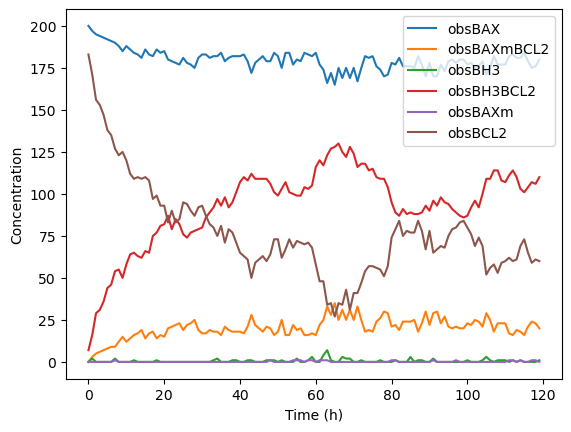

In [4]:
observables=['obsBAX','obsBAXmBCL2', 'obsBH3', 'obsBH3BCL2', 'obsBAXm', 'obsBCL2']; #plot Cyclin E, Cdc20 and Cyclin A
plotObs(model=simres_2.all, obs=observables, times=t, tpos=range(0,120), legend=True)

<Axes: xlabel='Time (h)', ylabel='Concentration'>

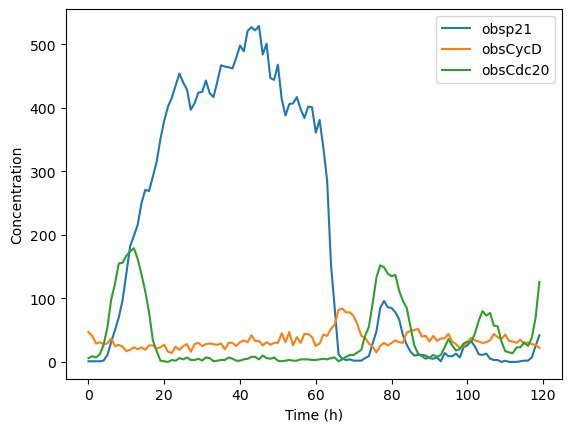

In [8]:
observables=['obsp21','obsCycD', 'obsCdc20']; #plot Cyclin E, Cdc20 and Cyclin A
plotObs(model=simres_2.all, obs=observables, times=t, tpos=range(0,120), legend=True)

In [ ]:
t_ode = np.linspace(0, 1000, 1000)  # Time points for ODE simulation
simres = ScipyOdeSimulator(model, t_ode, verbose=False).run()
plotObs(model=simres.all, obs=observables, times=t, tpos=range(0,300), legend=True)

In [ ]:
yout[model.observables['obsCdc20'].name]

In [ ]:
from Check_Model_Consistency import Check_Model_Consistency

In [ ]:
variable_range, check, tmp_score = Check_Model_Consistency(model, thr = 0.26, return_plot = False)

In [ ]:
variable_range

In [ ]:
death_mod={'obsBAX': 186 ,'obsBAXmBCL2': 13, 'obsBH3': 0, 'obsBH3BCL2': 7, 'obsBAXm': 0, 'obsBCL2': 149}
for prot in death_mod:
        variable_range[prot] = len(variable_range['obsCdc20'])*[death_mod[prot]]

In [ ]:
plt.plot(variable_range['obsBH3BCL2'])

In [ ]:
condition = "4 kPa erlotinib"
print(condition)

initial_concentrations = pd.read_csv(os.getcwd() + '/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

parameter_vector_original=[]
for pname in sampled_parameter_names:
    #Change model parameter values to current location in parameter space
    parameter_vector_original+=[model.parameters[pname].value]

In [ ]:
cond_split_DMSO = condition.split(' ')[0:2]
cond_split_DMSO.append('DMSO')
condition_untreated = ' '.join(cond_split_DMSO)
#Set initial condition to DMSO treatment
for signal_tmp in ['ERK', 'FAK', 'AKT'] :
    # print(ECM_conditions)
    # ECM_conditions has col condition to be matched with the input splt DMSO, for each species from species col, and value col
    model.parameters[signal_tmp].value = ECM_conditions[(ECM_conditions["condition"] == condition_untreated) & (ECM_conditions["species"] == signal_tmp)]["value"]

variable_range, check, tmp_score = Check_Model_Consistency(model, thr = 0.26, return_plot = False)

In [ ]:
model.parameters['ERK'].value

In [ ]:
plt.plot(variable_range['obsBCL2'])

In [ ]:
t_ode = np.linspace(0, 1000, 1000)  # Time points for ODE simulation
simres = ScipyOdeSimulator(model, t_ode, verbose=False).run()
yout = simres.all  # get simulation results

In [ ]:
plt.plot(yout['obs'])

In [ ]:
model.parameters['FAK'].value

In [ ]:
print(condition)

In [ ]:
initial_concentrations = pd.read_csv(os.getcwd() + '/model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

In [ ]:
parameter_vector_original=[]
for pname in sampled_parameter_names:
    #Change model parameter values to current location in parameter space
    parameter_vector_original+=[model.parameters[pname].value]

In [ ]:
cond_split_DMSO = condition.split(' ')[0:2]
cond_split_DMSO.append['DMSO']
condition_untreated = ' '.join(cond_split_DMSO)
#Set initial condition to DMSO treatment
for signal_tmp in ['ERK', 'FAK', 'AKT'] :
    # print(ECM_conditions)
    # ECM_conditions has col condition to be matched with the input splt DMSO, for each species from species col, and value col
    model.parameters[signal_tmp].value = ECM_conditions[(ECM_conditions["condition"] == condition_untreated) & (ECM_conditions["species"] == signal_tmp)]["value"]

In [ ]:
cond_split_DMSO = condition.split(' ')[0:2]
cond_split_DMSO.append('DMSO')
condition_untreated = ' '.join(cond_split_DMSO)

In [ ]:
condition_untreated

In [ ]:
ECM_conditions[(ECM_conditions["condition"] == condition_untreated) & (ECM_conditions["species"] == 'ERK')]["value"]

In [ ]:
model.parameters['ERK'].value